# ERA5: conditional forecasts and backcasts of air-parcel tracks with a Kinematic Interpolant

The trained model on true ERA5 parcel tracks, in the layout of the ocean notebook of the Kinematic Interpolant paper (Jiang, Marzouk, Bose & Pooladian, *Learning smooth dynamics via Kinematic Interpolants*, arXiv:2610.22519; `ki/notebooks/oceans_currents_interpolant.ipynb`). Steps:

1. read eight patches of true tracks (480 air parcels each, computed by LAGRANTO from hourly ERA5 winds) of the 2010 Russian block from the public Hugging Face dataset `yanxingjianken/blocking-tracks` (about 2.5 MB, by byte range; how the tracks are made: `scripts/era5_pfiles.py`, `scripts/11_tracks.py`, `scripts/12_dataset.py`);
2. load the conditional Kinematic Interpolant trained on 2015–2017 from the public Hugging Face model `yanxingjianken/ki-era5-tracks`;
3. **forecast**: from the tracks of 192 parcels of a patch over the 48 h before an anchor time, integrate 64 other parcels of the patch 24 h forward; **backcast**: from the 48 h after the anchor, integrate them 24 h backward; deterministically and as a 16-member ensemble;
4. compare with the true tracks and with straight motion.

The model never sees a wind field, and 2010 was not used in training. A GPU is used if there is one; on a CPU the whole notebook takes a few minutes.

## 1. Imports and settings

In [1]:
from pathlib import Path
import json, math, warnings
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
warnings.filterwarnings('ignore', message='IProgress not found')   # progress bars without ipywidgets
from huggingface_hub import HfFileSystem, hf_hub_download

DATA_REPO, MODEL_REPO = 'yanxingjianken/blocking-tracks', 'yanxingjianken/ki-era5-tracks'
EVENT = 'russia_2010'
RELEASE = '2010-07-30T00'                    # patches released here; anchors 24 h and 48 h later
SIGMAS = [0.38, 0.285]                       # start levels: pressure / surface pressure
NEAR = (57.0, 40.0)                          # the four patches whose centres are nearest this point (deg N, deg E)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
H_KM, A_KM = 7.0, 6371.0
print('device', DEVICE)

device cuda


## 2. True tracks from the public dataset
`index.json` lists every patch (release time, start level, centre); `tracks.npy` holds, per patch, the position (x, y in north-polar stereographic km, z = −7 km ln(p / 1000 hPa)) and velocity (km/h) of its 480 parcels every 3 h from release to 156 h, as float16 (positions to within a few km). Only the eight patch rows are read.

In [2]:
fs = HfFileSystem(); EV = f'datasets/{DATA_REPO}/{EVENT}'
idx = json.loads(fs.read_text(f'{EV}/index.json'))
NT, NP, NF = idx['row_shape']; STEP_H = idx['hours'][1] - idx['hours'][0]

def gc_deg(lat1, lon1, lat2, lon2):
    p1, p2, dl = np.deg2rad(lat1), np.deg2rad(lat2), np.deg2rad(lon2 - lon1)
    return np.rad2deg(np.arccos(np.clip(np.sin(p1) * np.sin(p2) + np.cos(p1) * np.cos(p2) * np.cos(dl), -1, 1)))

chosen = []
for s in SIGMAS:
    k = int(np.argmin(np.abs(np.array(idx['sigma']) - s)))
    rows = [p for p in idx['patches'] if p['release_time'] == RELEASE and p['level'] == k]
    chosen += sorted(rows, key=lambda p: gc_deg(*p['centre'], *NEAR))[:4]
with fs.open(f'{EV}/tracks.npy', 'rb') as f:
    version = np.lib.format.read_magic(f)
    shape, _, dtype = (np.lib.format.read_array_header_1_0 if version == (1, 0) else np.lib.format.read_array_header_2_0)(f)
    off, nbytes = f.tell(), NT * NP * NF * dtype.itemsize
    data = []
    for p in chosen:
        f.seek(off + p['row'] * nbytes); data.append(np.frombuffer(f.read(nbytes), dtype).reshape(NT, NP, NF))
data = np.stack(data).astype(np.float32)               # (patch, time every 3 h, parcel, x y z u v w)
X, V = data[..., :3], data[..., 3:]
LEVEL = np.array([idx['sigma'][p['level']] for p in chosen])
print(f"{len(chosen)} patches released {RELEASE}: {X.shape[2]} parcels x {X.shape[1]} times every {STEP_H} h; "
      f"centres {[tuple(p['centre']) for p in chosen[:4]]}")

8 patches released 2010-07-30T00: 480 parcels x 53 times every 3 h; centres [(60.0, 33.99), (52.0, 39.61), (60.0, 51.98), (52.0, 54.21)]


In [3]:
zm = json.loads(fs.read_text(f'{EV}/z500.json')); _, NZT, NY, NX = zm['shape']
def z500(t, field=0):
    """500-hPa height (field 0) or its departure from the zonal mean (field 1), m, at time t."""
    k = zm['times'].index(t)
    with fs.open(f'{EV}/z500.bin', 'rb') as f:
        f.seek(((field * NZT + k) * NY * NX) * 2); return np.frombuffer(f.read(NY * NX * 2), np.int16).reshape(NY, NX).astype(float)
ZLON, ZLAT = np.array(zm['lon'], float), np.array(zm['lat'])
ZLON = ZLON[0] + (ZLON - ZLON[0]) % 360        # increasing across 0 deg (e.g. 310 ... 460)

def xy_to_lonlat(x):
    r = np.hypot(x[..., 0], x[..., 1])
    return np.rad2deg(np.arctan2(x[..., 0], -x[..., 1])) % 360.0, 90.0 - np.rad2deg(2 * np.arctan(r / (2 * A_KM)))
hpa = lambda z: 1000.0 * np.exp(-z / H_KM)
t_of = lambda h: str(np.datetime64(RELEASE, 'h') + np.timedelta64(int(h), 'h'))

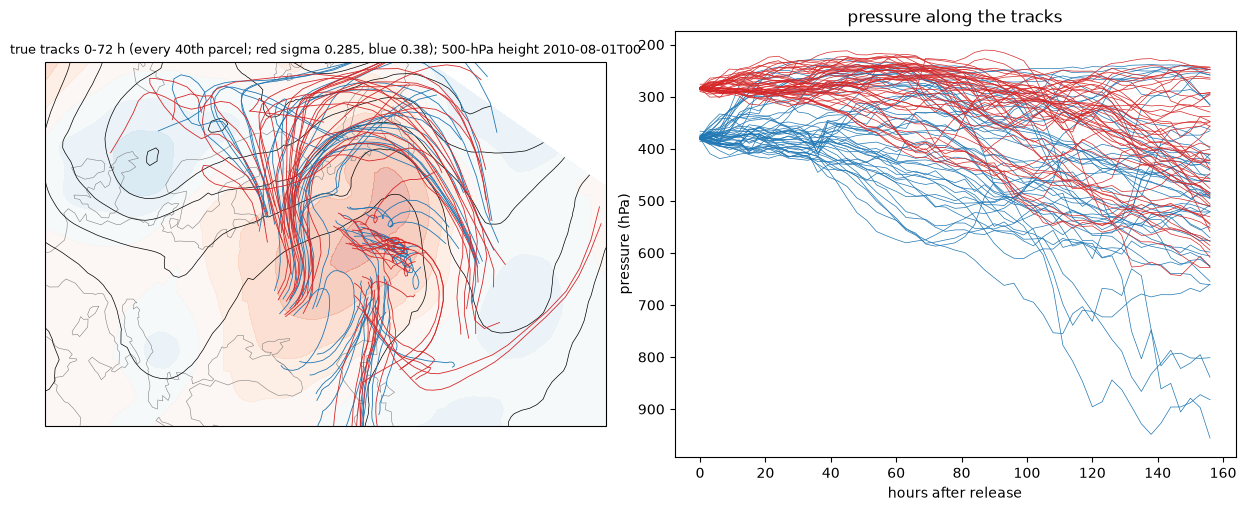

In [4]:
def base_map(ax, t):
    ax.set_extent([5, 85, 38, 78], ccrs.PlateCarree()); ax.coastlines(lw=0.4, color='0.5')
    ax.contourf(ZLON, ZLAT, z500(t, 1), levels=np.arange(-400, 401, 50), cmap='RdBu_r', alpha=0.45, transform=ccrs.PlateCarree())
    ax.contour(ZLON, ZLAT, z500(t), levels=np.arange(4800, 6000, 80), colors='k', linewidths=0.5, transform=ccrs.PlateCarree())

fig = plt.figure(figsize=(12, 5), layout='constrained')
ax = fig.add_subplot(1, 2, 1, projection=ccrs.NorthPolarStereo(central_longitude=45)); base_map(ax, t_of(48))
b = fig.add_subplot(1, 2, 2); th = STEP_H * np.arange(NT)
for i in range(len(chosen)):
    col = 'tab:red' if LEVEL[i] == SIGMAS[1] else 'tab:blue'
    for j in range(0, NP, 40):
        lo, la = xy_to_lonlat(X[i, :25, j]); ax.plot(lo, la, lw=0.6, color=col, transform=ccrs.Geodetic())
        b.plot(th, hpa(X[i, :, j, 2]), lw=0.5, color=col)
ax.set_title(f'true tracks 0-72 h (every 40th parcel; red sigma {SIGMAS[1]}, blue {SIGMAS[0]}); 500-hPa height {t_of(48)}', fontsize=9)
b.invert_yaxis(); b.set(xlabel='hours after release', ylabel='pressure (hPa)', title='pressure along the tracks')
plt.show()

## 3. The conditional Kinematic Interpolant
A parcel's state is its position (x, y, z) and velocity. Context tokens are the observed parcels of the patch every 3 h over 48 h: time from the anchor, position relative to the patch centroid at the anchor (absolute height), sin(latitude) and velocity, each axis divided by its scale. A Perceiver encoder compresses them into 96 latent vectors; a query state reads the latents by cross-attention and returns the acceleration and the scaled velocity score of the paper (code copied from `scripts/ctx_model.py`). The weights, the per-axis scales and the ensemble setting come from the public Hugging Face model.

In [5]:
N_FEAT = 8   # token and query features: time, x, y, z, sin(latitude), u, v, w


class Fourier(nn.Module):
    """Raw features plus sin/cos of the first `n_fourier` features at octave frequencies."""

    def __init__(self, n_in, n_fourier, octaves=6):
        super().__init__()
        self.n_fourier = n_fourier
        self.register_buffer("freqs", math.pi * 2.0 ** torch.arange(octaves, dtype=torch.float32))
        self.n_out = n_in + 2 * n_fourier * octaves

    def forward(self, z):
        f = z[..., : self.n_fourier, None] * self.freqs
        return torch.cat([z, torch.sin(f).flatten(-2), torch.cos(f).flatten(-2)], dim=-1)


class Block(nn.Module):
    """Pre-norm attention block (cross-attention when a context is given) with an MLP."""

    def __init__(self, d, heads, cross=False):
        super().__init__()
        self.nq = nn.LayerNorm(d)
        self.nk = nn.LayerNorm(d) if cross else None
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.mlp = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, q, kv=None, pad=None):
        h = self.nq(q)
        k = h if kv is None else self.nk(kv)
        q = q + self.attn(h, k, k, key_padding_mask=pad, need_weights=False)[0]
        return q + self.mlp(q)


def embed(n_in, n_fourier, d):
    f = Fourier(n_in, n_fourier)
    return nn.Sequential(f, nn.Linear(f.n_out, d), nn.GELU(), nn.Linear(d, d))


class ContextKI(nn.Module):
    """Perceiver encoder over context tokens and a cross-attention decoder for query states.

    Token features: (tau, x, y, z, sin lat, u, v, w); query features: the same for the state to be advanced.
    """

    def __init__(self, d=384, heads=8, latents=96, enc_layers=6, dec_layers=3):
        super().__init__()
        self.tok, self.qry = embed(N_FEAT, 4, d), embed(N_FEAT, 4, d)
        self.latents = nn.Parameter(torch.randn(latents, d) * 0.02)
        self.read = Block(d, heads, cross=True)
        self.enc = nn.ModuleList([Block(d, heads) for _ in range(enc_layers)])
        self.dec = nn.ModuleList([Block(d, heads, cross=True) for _ in range(dec_layers)])
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, 6))
        nn.init.zeros_(self.head[1].weight)
        nn.init.zeros_(self.head[1].bias)

    def encode(self, tokens, pad=None):
        """tokens (B, M, 8), pad (B, M) True where absent -> latents (B, L, d)."""
        z = self.latents.expand(tokens.shape[0], -1, -1)
        z = self.read(z, self.tok(tokens), pad)
        for blk in self.enc:
            z = blk(z)
        return z

    def decode(self, z, queries):
        """queries (B, Q, 8) -> acceleration (B, Q, 3) and scaled score (B, Q, 3)."""
        h = self.qry(queries)
        for blk in self.dec:
            h = blk(h, z)
        out = self.head(h)
        return out[..., :3], out[..., 3:]

    def forward(self, tokens, pad, queries):
        return self.decode(self.encode(tokens, pad), queries)

In [6]:
ck = torch.load(hf_hub_download(MODEL_REPO, 'context_ki_era5.pt'), map_location=DEVICE, weights_only=False)
ens = json.loads(Path(hf_hub_download(MODEL_REPO, 'ensemble.json')).read_text())
model = ContextKI(d=ck['args']['d_model']).to(DEVICE).eval(); model.load_state_dict(ck['state'])
SC = ck['scales']; tt = lambda v: torch.tensor(np.asarray(v), dtype=torch.float32, device=DEVICE)
POS, VEL, ACC, TIME_H = tt(SC['pos_km']), tt(SC['vel_kmh']), tt(SC['acc_kmh2']), float(SC['time_h'])
SIGMA_V = tt([5.0, 5.0, 0.01]) * float(np.pi * np.sqrt(3) / 6.0)   # training noise in velocity (km/h)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters, trained {ck['args']['steps']:,} steps "
      f"(weights of step {ck['step']:,}); scales {SC['vel_kmh']} km/h, {SC['acc_kmh2']} km/h2; ensemble eps_rel {ens['eps_rel']}")

32.2 M parameters, trained 200,000 steps (weights of step 158,000); scales [62.02, 60.74, 0.08518] km/h, [5.366, 5.411, 0.1245] km/h2; ensemble eps_rel 1.5


## 4. Forecasts and backcasts
**Forecast** at anchor 48 h after release: the context is 192 parcels of the patch observed every 3 h over 0–48 h; 64 other parcels start from their true state at 48 h and are integrated to 72 h. **Backcast** at anchor 24 h: the context is observed over 24–72 h; the parcels are integrated backward to 0 h. Deterministic tracks follow x' = v, v' = a (Heun, 10-minute steps); ensemble members add the score term and random kicks, dv = [a + (eps²/2) s / sigma_v] dt + eps dW with eps = eps_rel sigma_v, so that the spread matches the error on validation data. Straight motion keeps the anchor velocity.

In [7]:
def sin_lat(x):
    r = torch.hypot(x[..., 0], x[..., 1]); return torch.cos(2 * torch.atan(r / (2 * A_KM)))

def tokens(Xp, Vp, r0, d, ctx):
    """Context of one patch: 17 rows every 3 h from the anchor row r0 backward (d = 1) or forward (d = -1)."""
    rows = r0 - d * np.arange(17); Xc, Vc = tt(Xp[rows][:, ctx]), tt(Vp[rows][:, ctx])
    cen = tt(Xp[r0, :, :2].mean(0))
    tau = tt(-d * STEP_H * np.arange(17) / TIME_H)[:, None, None].expand(17, len(ctx), 1)
    rel = torch.cat([Xc[..., :2] - cen, Xc[..., 2:]], -1)
    return torch.cat([tau, rel / POS, sin_lat(Xc)[..., None], Vc / VEL], -1).reshape(1, -1, 8), cen

def heads(z, cen, tau, x, v):
    rel = torch.cat([x[..., :2] - cen, x[..., 2:]], -1)
    a, s = model.decode(z, torch.cat([tau / TIME_H, rel / POS, sin_lat(x)[..., None], v / VEL], -1))
    return a * ACC, s

@torch.no_grad()
def integrate(tok, cen, x0, v0, d, members=0, hours=24, sph=6, seed=0):
    """members = 0: deterministic (Heun); else Euler-Maruyama ensemble. Returns hourly positions (hours + 1, M, Q, 3)."""
    z = model.encode(tok); g = torch.Generator(device=DEVICE).manual_seed(seed)
    m = max(members, 1); x = tt(x0)[None].repeat(m, 1, 1).reshape(1, -1, 3); v = tt(v0)[None].repeat(m, 1, 1).reshape(1, -1, 3)
    dt = d / sph; eps = ens['eps_rel'] * SIGMA_V; out = [x.clone()]
    for k in range(hours * sph):
        tau = torch.full_like(x[..., :1], k * dt); a, s = heads(z, cen, tau, x, v)
        if members == 0:
            xp, vp = x + dt * v, v + dt * a; a1, _ = heads(z, cen, tau + dt, xp, vp)
            x, v = x + 0.5 * dt * (v + vp), v + 0.5 * dt * (a + a1)
        else:
            x, v = x + dt * v, v + dt * a + abs(dt) * 0.5 * eps ** 2 * s / SIGMA_V + eps * np.sqrt(abs(dt)) * torch.randn(x.shape, device=DEVICE, generator=g)
        if (k + 1) % sph == 0: out.append(x.clone())
    return torch.stack(out).reshape(hours + 1, m, -1, 3).cpu().numpy()

def gc_km(xa, xb):
    (l1, p1), (l2, p2) = xy_to_lonlat(xa), xy_to_lonlat(xb)
    return A_KM * np.deg2rad(gc_deg(p1, l1, p2, l2))

rows, keep = [], {}
for i in range(len(chosen)):
    perm = np.random.default_rng(i).permutation(NP); ctx, tgt = perm[:192], perm[192:256]
    for task, d, t0 in (('forecast', 1, 48), ('backcast', -1, 24)):
        r0 = t0 // STEP_H; tok, cen = tokens(X[i], V[i], r0, d, ctx)
        det = integrate(tok, cen, X[i, r0, tgt], V[i, r0, tgt], d)[:, 0]
        ensm = integrate(tok, cen, X[i, r0, tgt], V[i, r0, tgt], d, members=ens['members'], seed=i)
        for h in (6, 12, 24):
            truth = X[i, r0 + d * h // STEP_H, tgt]
            straight = X[i, r0, tgt] + d * h * V[i, r0, tgt]
            for name, pred in (('model', det[h]), ('ensemble mean', ensm[h].mean(0)), ('straight motion', straight)):
                rows.append(dict(level=LEVEL[i], patch=i, task=task, horizon_h=h, method=name,
                                 error_km=float(np.median(gc_km(pred, truth))),
                                 error_hpa=float(np.median(np.abs(hpa(pred[:, 2]) - hpa(truth[:, 2]))))))
        keep[(i, task)] = (tgt, det, ensm)
res = pd.DataFrame(rows)
res.pivot_table(index=['task', 'horizon_h'], columns='method', values='error_km', aggfunc='median').round(0)

method              ensemble mean  model  straight motion
task     horizon_h                                       
backcast 6                   24.0   25.0             32.0
         12                  75.0   86.0            106.0
         24                 240.0  337.0            263.0
forecast 6                   35.0   36.0             65.0
         12                 115.0  152.0            240.0
         24                 441.0  520.0            761.0

In [8]:
res.pivot_table(index=['task', 'horizon_h'], columns='method', values='error_hpa', aggfunc='median').round(1)

method              ensemble mean  model  straight motion
task     horizon_h                                       
backcast 6                    8.5    9.3             10.4
         12                  12.2   15.4             23.0
         24                  12.0   16.0             46.3
forecast 6                    8.8    8.5             10.0
         12                  17.0   19.0             19.9
         24                  30.5   34.4             43.7

## 5. Tracks against the truth
One patch at sigma 0.285: true tracks every 3 h (black dashed), the deterministic model (red), the ensemble members (light red) and straight motion (grey) over the 500-hPa height (contours) and its departure from the zonal mean (shading) at the anchor time; left the forecast from 48 to 72 h, right the backcast from 24 back to 0 h.

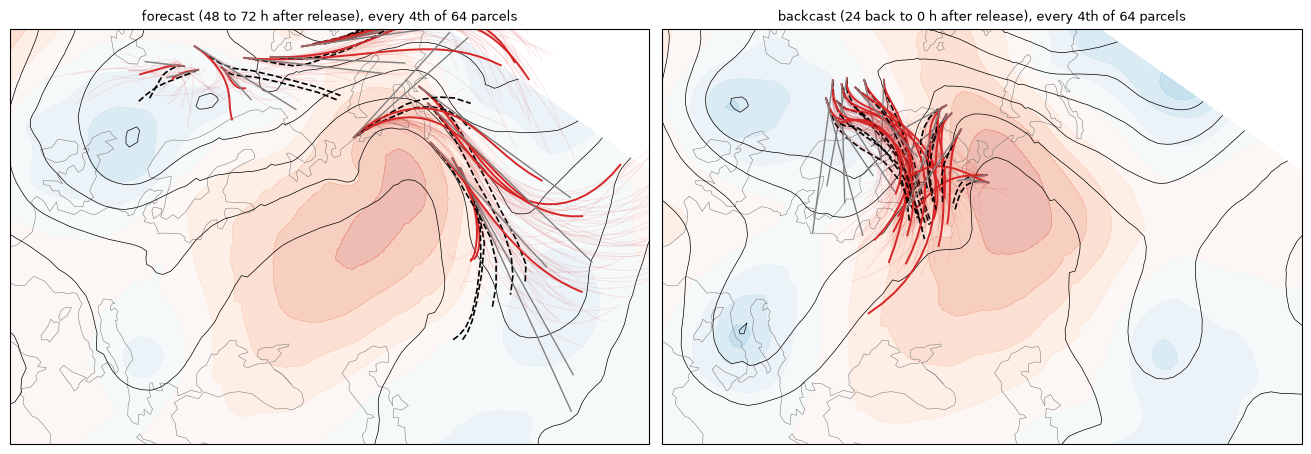

In [9]:
i = int(np.flatnonzero(LEVEL == SIGMAS[1])[0])
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), layout='constrained', subplot_kw=dict(projection=ccrs.NorthPolarStereo(central_longitude=45)))
for ax, (task, d, t0) in zip(axes, (('forecast', 1, 48), ('backcast', -1, 24))):
    tgt, det, ensm = keep[(i, task)]; r0 = t0 // STEP_H; base_map(ax, t_of(t0))
    for j in range(0, len(tgt), 4):
        for m in range(ensm.shape[1]):
            lo, la = xy_to_lonlat(ensm[:, m, j]); ax.plot(lo, la, color='tab:red', alpha=0.12, lw=0.6, transform=ccrs.Geodetic())
        for path, sty in ((X[i, r0 + d * np.arange(9), tgt[j]], dict(color='k', ls='--', lw=1.2)), (det[:, j], dict(color='tab:red', lw=1.4)),
                          (X[i, r0, tgt[j]] + d * np.arange(25)[:, None] * V[i, r0, tgt[j]], dict(color='0.5', lw=1))):
            lo, la = xy_to_lonlat(path); ax.plot(lo, la, transform=ccrs.Geodetic(), **sty)
    ax.set_title(f'{task} ({"48 to 72" if d > 0 else "24 back to 0"} h after release), every 4th of 64 parcels', fontsize=9)
plt.show()

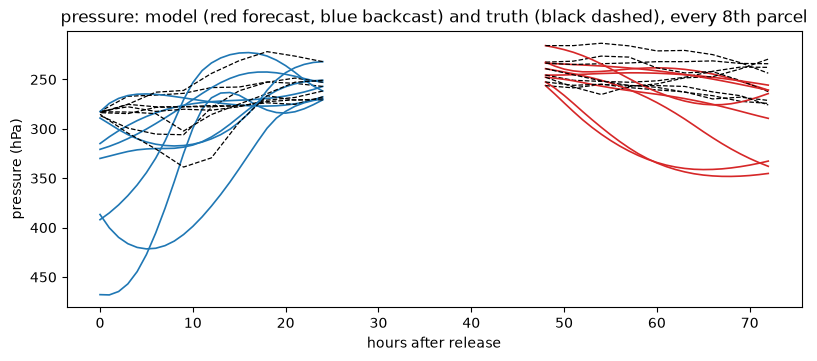

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
for task, d, t0, col in (('forecast', 1, 48, 'tab:red'), ('backcast', -1, 24, 'tab:blue')):
    tgt, det, ensm = keep[(i, task)]; r0 = t0 // STEP_H
    for j in range(0, len(tgt), 8):
        ax.plot(t0 + d * np.arange(25), hpa(det[:, j, 2]), color=col, lw=1.2)
        ax.plot(t0 + d * STEP_H * np.arange(9), hpa(X[i, r0 + d * np.arange(9), tgt[j], 2]), color='k', ls='--', lw=0.9)
ax.invert_yaxis(); ax.set(xlabel='hours after release', ylabel='pressure (hPa)',
                          title='pressure: model (red forecast, blue backcast) and truth (black dashed), every 8th parcel')
plt.show()